```markdown
# Model Evaluation
Evaluating all trained classifiers on the held-out test set.
Metrics: Accuracy, F1 Score, ROC-AUC, Confusion Matrix.
> Note: GBC uses threshold 0.66 | SVM uses threshold 0.20
```

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Train-test split
from sklearn.model_selection import train_test_split

import xgboost as xgb
import lightgbm as lgb



```markdown
## Load Models & Scaler
```

In [ ]:
scaler    = joblib.load('../exports/scaler.sav')

_gbc_raw     = joblib.load('../exports/gbc_model_optimised.sav')
knn_model    = joblib.load('../exports/knn.sav')
logreg_model = joblib.load('../exports/logreg.sav')
rf_model     = joblib.load('../exports/randomforest.sav')
_svm_raw     = joblib.load('../exports/svm_model_optimised.sav')
xgb_model = joblib.load('../exports/xgb_model.sav')
lgb_model  = joblib.load('../exports/lgb_model.sav')

# Unwrap optimised models
gbc_model = _gbc_raw['model']
gbc_threshold = _gbc_raw['threshold']

svm_model = _svm_raw['model']
svm_threshold = _svm_raw['threshold']

trained_models = {
    "GBC (opt)"    : (gbc_model,    gbc_threshold),
    "KNN"          : (knn_model,    None),
    "Logistic Reg" : (logreg_model, None),
    "Random Forest": (rf_model,     None),
    "SVM (opt)"    : (svm_model,    svm_threshold),
    "XGBoost"      : (xgb_model,    None),   # ← add
    "LightGBM"     : (lgb_model,    None),   # ← add
}

# Sanity check
for name, (mdl, thr) in trained_models.items():
    print(f"{name:20s} | threshold={thr} | type={type(mdl).__name__}")

GBC (opt)            | threshold=0.66 | type=GradientBoostingClassifier
KNN                  | threshold=None | type=KNeighborsClassifier
Logistic Reg         | threshold=None | type=LogisticRegression
Random Forest        | threshold=None | type=RandomForestClassifier
SVM (opt)            | threshold=0.2 | type=CalibratedClassifierCV
XGBoost              | threshold=None | type=XGBClassifier
LightGBM             | threshold=None | type=LGBMClassifier


In [ ]:
df = pd.read_csv("../data/cleaned_data.csv")

# Separate input features and target variable
X = df.drop('Response', axis=1)
y = df['Response']

# Split dataset into train and test sets
# stratify=y ensures same class distribution in both sets (important for imbalance)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_cols = [
    'Age',
    'Annual_Premium',
    'Vintage',
    'Region_Code',
    'Policy_Sales_Channel'
]


# Fit ONLY on training data
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# Transform test data
X_test[num_cols] = scaler.transform(X_test[num_cols])

```markdown
## Evaluation Loop
Each model is evaluated with its designated threshold where applicable.
```


Model     : GBC (opt)
Threshold : 0.66
Accuracy  : 0.7654
F1 Score  : 0.4584
ROC-AUC   : 0.8568

Confusion Matrix:


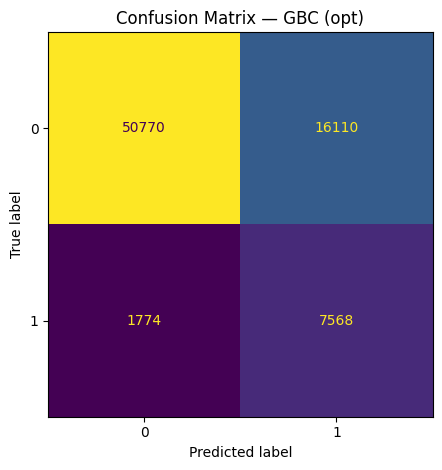


Model     : KNN
Threshold : 0.5
Accuracy  : 0.8552
F1 Score  : 0.2250
ROC-AUC   : 0.7539

Confusion Matrix:


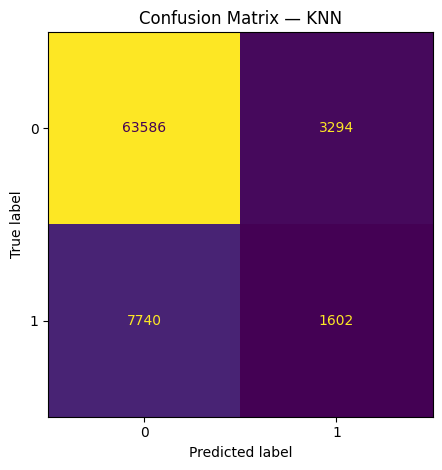


Model     : Logistic Reg
Threshold : 0.5
Accuracy  : 0.6402
F1 Score  : 0.3995
ROC-AUC   : 0.8344

Confusion Matrix:


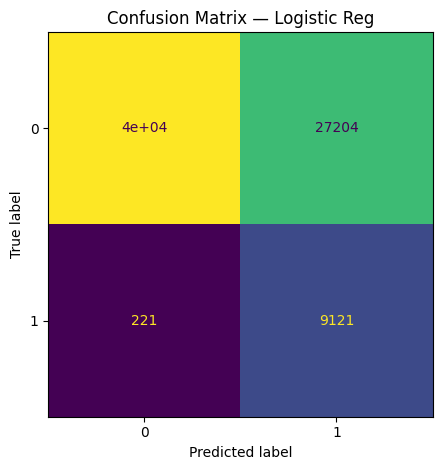


Model     : Random Forest
Threshold : 0.5
Accuracy  : 0.8685
F1 Score  : 0.1762
ROC-AUC   : 0.8323

Confusion Matrix:


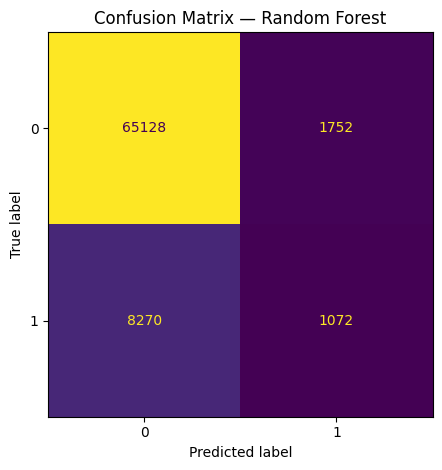


Model     : SVM (opt)
Threshold : 0.2
Accuracy  : 0.7449
F1 Score  : 0.4331
ROC-AUC   : 0.8344

Confusion Matrix:


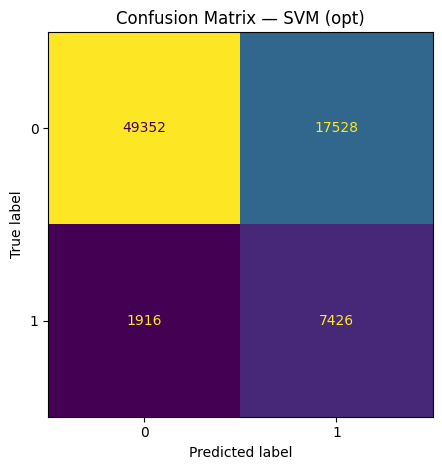


Model     : XGBoost
Threshold : 0.5
Accuracy  : 0.7070
F1 Score  : 0.4356
ROC-AUC   : 0.8578

Confusion Matrix:


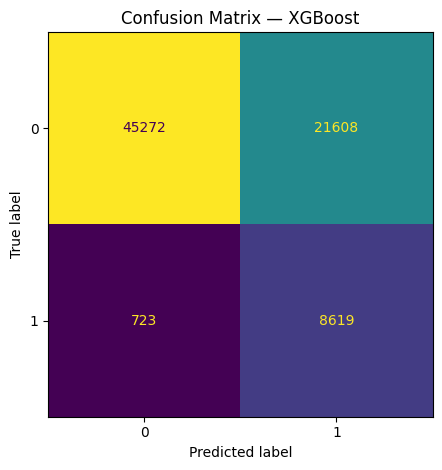


Model     : LightGBM
Threshold : 0.5
Accuracy  : 0.7075
F1 Score  : 0.4362
ROC-AUC   : 0.8578

Confusion Matrix:


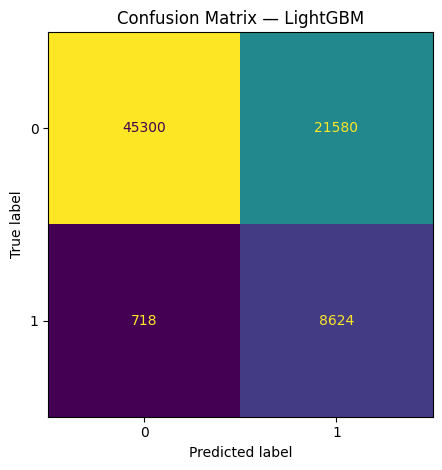

In [4]:
results = []

for name, (model, threshold) in trained_models.items():

    # --- Probabilities / scores ---
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        # SVM fallback — scale scores to [0,1] range for AUC
        scores = model.decision_function(X_test)
        y_prob = (scores - scores.min()) / (scores.max() - scores.min())
    else:
        y_prob = None

    # --- Apply custom threshold if set, else use default 0.5 ---
    if y_prob is not None:
        t = threshold if threshold is not None else 0.5
        y_pred = (y_prob >= t).astype(int)
    else:
        y_pred = model.predict(X_test)

    # --- Metrics ---
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else None

    print(f"\n{'='*40}")
    print(f"Model     : {name}")
    print(f"Threshold : {threshold if threshold else 0.5}")
    print(f"Accuracy  : {acc:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print(f"ROC-AUC   : {auc:.4f}" if auc else "ROC-AUC  : N/A")
    print("\nConfusion Matrix:")
    
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(colorbar=False)
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

    results.append([name, threshold, acc, f1, auc])

```markdown
## Results Table
```

In [5]:
results_df = pd.DataFrame(
    results,
    columns=["Model", "Threshold", "Accuracy", "F1 Score", "ROC-AUC"]
)

results_df.style.highlight_max(
    subset=["Accuracy", "F1 Score", "ROC-AUC"],
    color="lightgreen"
)

,Model,Threshold,Accuracy,F1 Score,ROC-AUC
0,GBC (opt),0.660000,0.765370,0.458389,0.856795
1,KNN,nan,0.855239,0.225032,0.753852
2,Logistic Reg,nan,0.640196,0.399457,0.834387
3,Random Forest,nan,0.868516,0.176229,0.832309
4,SVM (opt),0.200000,0.744903,0.433053,0.834360
5,XGBoost,nan,0.707027,0.435644,0.857792
6,LightGBM,nan,0.707460,0.436150,0.857818


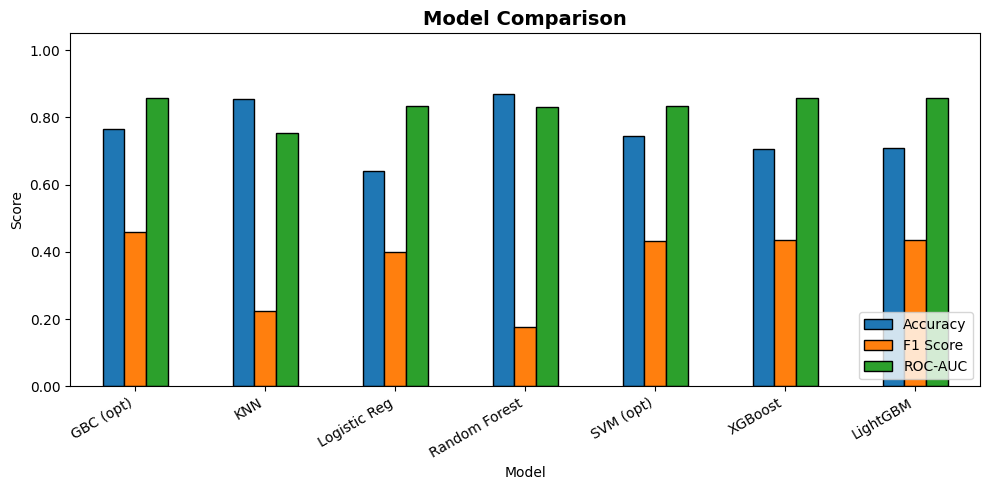

In [6]:
ax = results_df.set_index("Model")[["Accuracy", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5), edgecolor="black"
)

ax.set_title("Model Comparison", fontsize=14, fontweight="bold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
ax.legend(loc="lower right")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [10]:
best_row = results_df.sort_values(
    ["ROC-AUC", "F1 Score"],
    ascending=False
).iloc[0]

best_model_name = best_row["Model"]
best_auc        = best_row["ROC-AUC"]
best_f1         = best_row["F1 Score"]

print(f"Best Model : {best_model_name}")
print(f"ROC-AUC    : {best_auc:.4f}")
print(f"F1 Score   : {best_f1:.4f}")

Best Model : LightGBM
ROC-AUC    : 0.8578
F1 Score   : 0.4362
